# Child Mortality & Life Expectancy (1800–2024)

How have child mortality and life expectancy changed worldwide over two centuries, and how do they relate?
Data comes from two country-level [Gapminder](https://www.gapminder.org/data/) time series
(`lex.csv` = life expectancy, `child_mortality_0_5_year_olds_dying_per_1000_born.csv`).

**Steps:** reshape wide → long with `melt`, merge the two datasets on country and year, then draw four charts
(also saved to `figures/`).

**Libraries:** Pandas (melt, merge, groupby, pivot), Matplotlib

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Plot style
plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

FIG_DIR = Path('../../figures')
FIG_DIR.mkdir(exist_ok=True)

## Load and reshape the data

Both files are in *wide* format (one column per year). We melt them to *long* format and merge.

In [2]:
df_child = pd.read_csv('../../data/child_mortality_0_5_year_olds_dying_per_1000_born.csv')
df_lex = pd.read_csv('../../data/lex.csv')

years = [str(y) for y in range(1800, 2025)]

df_child_long = df_child.melt(
    id_vars=['geo', 'name'],
    value_vars=years,
    var_name='year',
    value_name='child_mortality',
)
df_lex_long = df_lex.melt(
    id_vars=['geo', 'name'],
    value_vars=years,
    var_name='year',
    value_name='life_expectancy',
)

df_child_long['year'] = df_child_long['year'].astype(int)
df_lex_long['year'] = df_lex_long['year'].astype(int)

df_merged = pd.merge(df_child_long, df_lex_long, on=['geo', 'name', 'year'])
print(df_merged.shape)
df_merged.head()

(43650, 5)


   geo         name  year  child_mortality  life_expectancy
0  afg  Afghanistan  1800           468.58            28.21
1  ago       Angola  1800           485.68            26.98
2  alb      Albania  1800           375.20            35.40
3  and      Andorra  1800              NaN              NaN
4  are          UAE  1800           434.46            30.70

## Chart 1: Global trend (1800–2024)

Unweighted mean across countries, with child mortality on the left axis and life expectancy on the right axis.

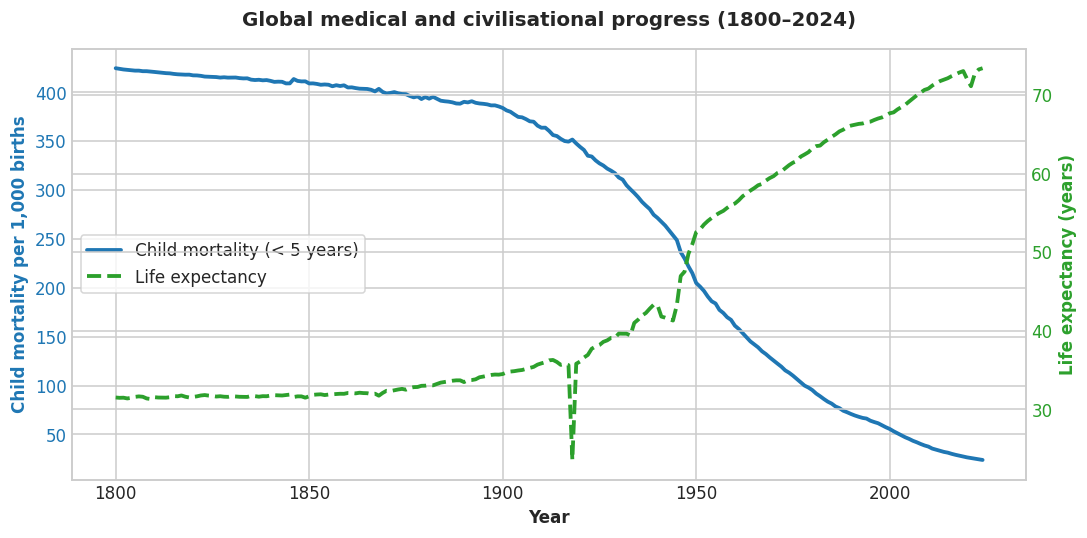

In [3]:
global_avg = (
    df_merged.groupby('year')[['child_mortality', 'life_expectancy']]
    .mean()
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(10, 5), dpi=150)
color = '#1f77b4'
ax1.set_xlabel('Year', fontsize=11, fontweight='bold')
ax1.set_ylabel('Child mortality per 1,000 births', color=color, fontsize=11, fontweight='bold')
line1 = ax1.plot(
    global_avg['year'],
    global_avg['child_mortality'],
    color=color,
    linewidth=2.5,
    label='Child mortality (< 5 years)',
)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Life expectancy (years)', color=color, fontsize=11, fontweight='bold')
line2 = ax2.plot(
    global_avg['year'],
    global_avg['life_expectancy'],
    color=color,
    linewidth=2.5,
    linestyle='--',
    label='Life expectancy',
)
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left', frameon=True, facecolor='white')

plt.title('Global medical and civilisational progress (1800–2024)', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIG_DIR / 'chart_1_global_trend.png', dpi=150, bbox_inches='tight')
plt.show()

## Chart 2: Child mortality vs. life expectancy at milestone years

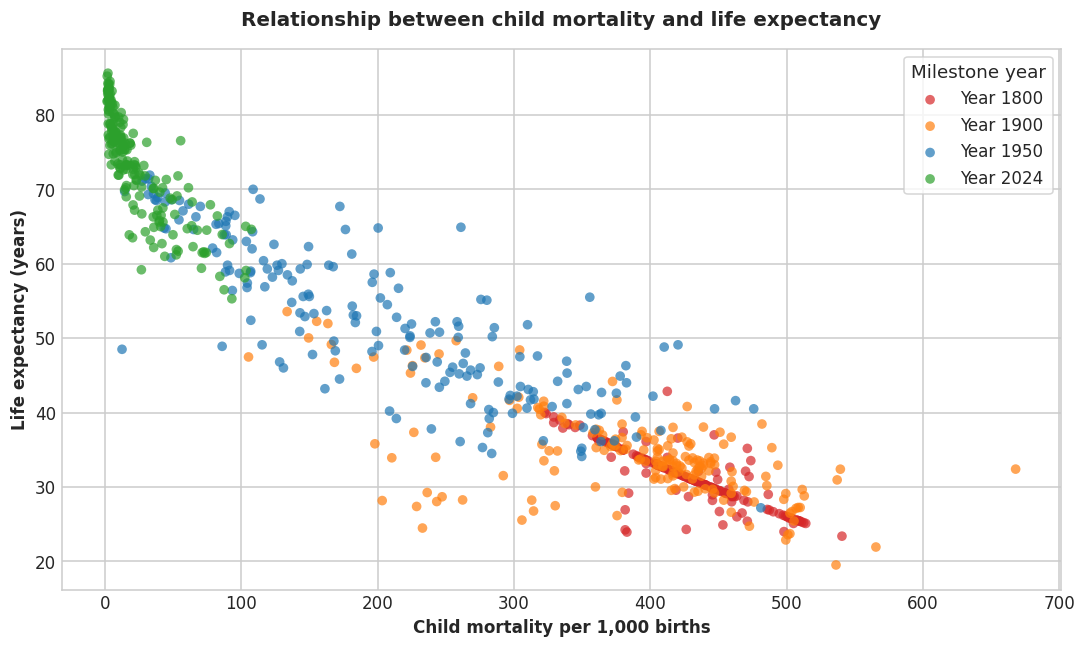

In [4]:
plt.figure(figsize=(10, 6), dpi=150)
sample_years = [1800, 1900, 1950, 2024]
colors = ['#d62728', '#ff7f0e', '#1f77b4', '#2ca02c']

for y, col in zip(sample_years, colors):
    subset = df_merged[df_merged['year'] == y]
    plt.scatter(
        subset['child_mortality'],
        subset['life_expectancy'],
        alpha=0.7,
        label=f'Year {y}',
        color=col,
        edgecolors='none',
        s=40,
    )

plt.title('Relationship between child mortality and life expectancy', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Child mortality per 1,000 births', fontsize=11, fontweight='bold')
plt.ylabel('Life expectancy (years)', fontsize=11, fontweight='bold')
plt.legend(title='Milestone year', frameon=True)
plt.tight_layout()
plt.savefig(FIG_DIR / 'chart_2_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## Chart 3: Impact of historical crises on life expectancy

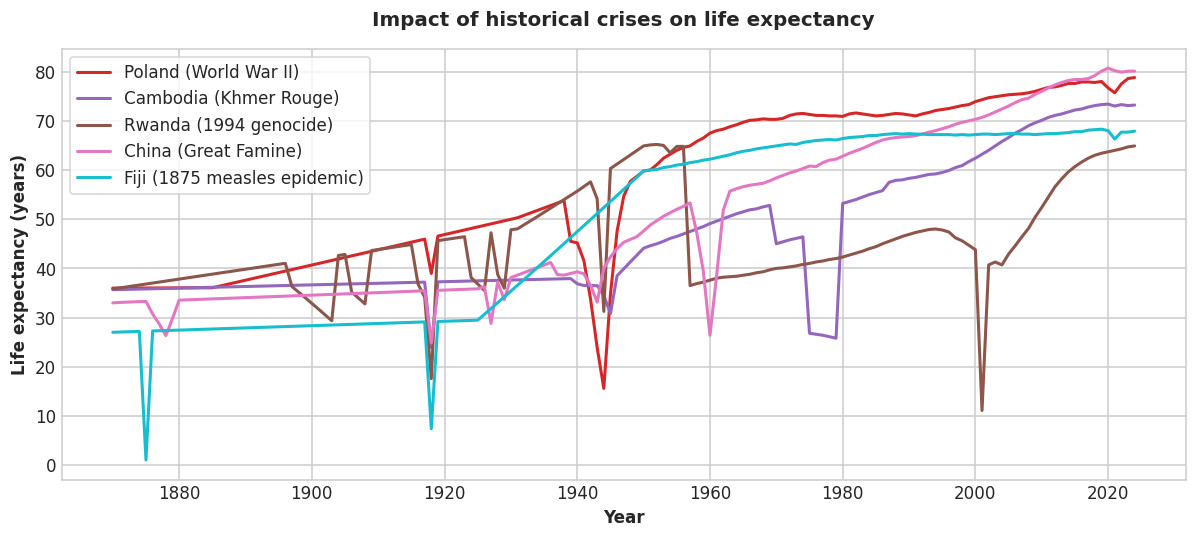

In [5]:
plt.figure(figsize=(11, 5), dpi=150)
crises_countries = [
    ('pol', 'Poland (World War II)', '#d62728'),
    ('khm', 'Cambodia (Khmer Rouge)', '#9467bd'),
    ('rwa', 'Rwanda (1994 genocide)', '#8c564b'),
    ('chn', 'China (Great Famine)', '#e377c2'),
    ('fji', 'Fiji (1875 measles epidemic)', '#17becf'),
]

for geo_code, label_name, col in crises_countries:
    c_data = df_merged[(df_merged['geo'] == geo_code) & (df_merged['year'] >= 1870)]
    plt.plot(c_data['year'], c_data['life_expectancy'], label=label_name, color=col, linewidth=2)

plt.title('Impact of historical crises on life expectancy', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=11, fontweight='bold')
plt.ylabel('Life expectancy (years)', fontsize=11, fontweight='bold')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig(FIG_DIR / 'chart_3_crises.png', dpi=150, bbox_inches='tight')
plt.show()

## Chart 4: Countries with the biggest gain in life expectancy (1950–2024)

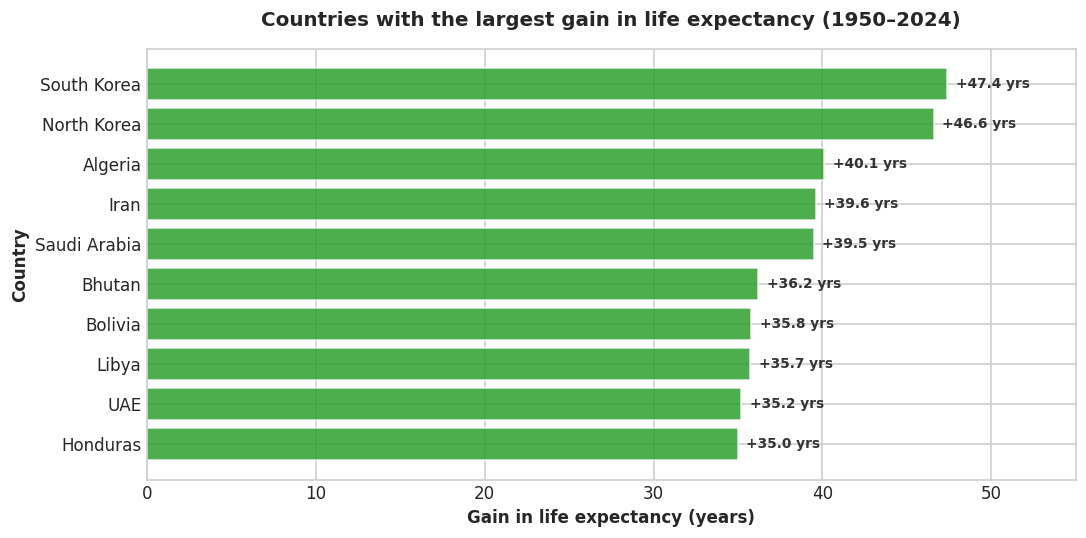

In [6]:
df_1950_2024 = (
    df_merged[df_merged['year'].isin([1950, 2024])]
    .pivot(index='name', columns='year', values='life_expectancy')
    .dropna()
)
df_1950_2024['gain'] = df_1950_2024[2024] - df_1950_2024[1950]
top10 = df_1950_2024.sort_values(by='gain', ascending=True).tail(10)

plt.figure(figsize=(10, 5), dpi=150)
bars = plt.barh(top10.index, top10['gain'], color='#2ca02c', alpha=0.85)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f'+{width:.1f} yrs',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='#333333',
    )

plt.xlim(0, 55)
plt.title('Countries with the largest gain in life expectancy (1950–2024)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Gain in life expectancy (years)', fontsize=11, fontweight='bold')
plt.ylabel('Country', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / 'chart_4_top_gains.png', dpi=150, bbox_inches='tight')
plt.show()